In [90]:
import numpy as np
from lib.dvr1d import *
from lib.utils import *
from lib.vqe import DVR_VQE
from lib.pot_gen import get_pot_cr2
from qiskit.circuit.library import TwoLocal

import matplotlib.pyplot as plt
from matplotlib import rc

log_file = 'results/log.txt'

cmap = plt.get_cmap('tab10')
plt.rcParams["figure.figsize"] = (5,5)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 300
rc('text', usetex=True)
rc('font',**{'family':'serif','serif':['Computer Modern']})
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [91]:
mol_params = cr2_params
spin = 13
mol_params['name'] += f'_{spin}'

# 16 points
params16 = [5.2, 9]
dvr_options = {
    'type': '1d',
    'box_lims': (params16[0], params16[1]),
    'dx': (params16[1] - params16[0]) / 16,
    'count': 16
}
vqe_options = {
    'optimizers': ['L_BFGS_B.1000'],
    # 'optimizers': ['COBYLA.10'],
    # 'repeats': 1, 
    'repeats': 5, 
    'beta': [10000 for i in range(5)],
    'seed': 42
}

ansatz_options = {
    'type': 'twolocal',
    'entanglement': 'opt',
    'gates': [3, 1, 9],
    'reps': 2,
}

In [92]:
import qiskit
import qiskit_algorithms
import qiskit_aer

print(qiskit.__version__)
print(qiskit_algorithms.__version__)
print(qiskit_aer.__version__)

2.2.3
0.4.0
0.17.2


In [93]:
%autoreload
pot, lims = get_pot_cr2(spin)
dvr_vqe = DVR_VQE(mol_params, pot, log_dir='results/excited_states/')
# dvr_vqe = DVR_VQE(mol_params, pot, log_dir='results/excited_states/', noise_model='sherbrooke')
opt_params = dvr_vqe.get_dvr_vqe(dvr_options, ansatz_options, vqe_options, excited_states=True)

     ┌─────────────┐ ░            ░ ┌─────────────┐ ░       ░                
q_0: ┤ Ry($x_{0}$) ├─░───■────────░─┤ Ry($x_{4}$) ├─░───────░────────────────
     ├─────────────┤ ░   │        ░ ├─────────────┤ ░       ░ ┌─────────────┐
q_1: ┤ Ry($x_{1}$) ├─░───┼────■───░─┤ Ry($x_{5}$) ├─░───■───░─┤ Ry($x_{7}$) ├
     ├─────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ ├─────────────┤ ░ ┌─┴─┐ ░ ├─────────────┤
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├┤ X ├─░─┤ Ry($x_{6}$) ├─░─┤ X ├─░─┤ Ry($x_{8}$) ├
     ├─────────────┤ ░ └───┘└───┘ ░ └─────────────┘ ░ └───┘ ░ └─────────────┘
q_3: ┤ Ry($x_{3}$) ├─░────────────░─────────────────░───────░────────────────
     └─────────────┘ ░            ░                 ░       ░                
-----------------------------------------
Optimizer: L_BFGS_B        
57, -461.90716985593184

KeyboardInterrupt: 

In [38]:
ansatz_options2 = {
    'type': 'twolocal',
    'entanglement': 'opt',
    'gates': [3, 1, 9, 4, 8],
    'reps': 2,
}

opt_params2 = dvr_vqe.get_dvr_vqe(dvr_options, ansatz_options2, vqe_options, excited_states=True)

     ┌─────────────┐ ░                 ░ ┌─────────────┐ ░            ░ »
q_0: ┤ Ry($x_{0}$) ├─░───■─────────────░─┤ Ry($x_{4}$) ├─░───■────────░─»
     ├─────────────┤ ░   │             ░ ├─────────────┤ ░   │        ░ »
q_1: ┤ Ry($x_{1}$) ├─░───┼────■────■───░─┤ Ry($x_{5}$) ├─░───┼────■───░─»
     ├─────────────┤ ░ ┌─┴─┐┌─┴─┐  │   ░ ├─────────────┤ ░   │  ┌─┴─┐ ░ »
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├┤ X ├──┼───░─┤ Ry($x_{6}$) ├─░───┼──┤ X ├─░─»
     ├─────────────┤ ░ └───┘└───┘┌─┴─┐ ░ ├─────────────┤ ░ ┌─┴─┐└───┘ ░ »
q_3: ┤ Ry($x_{3}$) ├─░───────────┤ X ├─░─┤ Ry($x_{7}$) ├─░─┤ X ├──────░─»
     └─────────────┘ ░           └───┘ ░ └─────────────┘ ░ └───┘      ░ »
«     ┌─────────────┐ 
«q_0: ┤ Ry($x_{8}$) ├─
«     ├─────────────┤ 
«q_1: ┤ Ry($x_{9}$) ├─
«     ├─────────────┴┐
«q_2: ┤ Ry($x_{10}$) ├
«     ├──────────────┤
«q_3: ┤ Ry($x_{11}$) ├
«     └──────────────┘
-----------------------------------------
Optimizer: L_BFGS_B        
1001, -548.6717542173843
1001, -548.6662110375994
1001, -

In [39]:
np.savez('results/excited_states/opt_params.npz', opt_params=opt_params, opt_params2=opt_params2)

In [94]:
with np.load('results/excited_states/opt_params.npz') as f:
    opt_params = f['opt_params']
    opt_params2 = f['opt_params2']

In [40]:
h_dvr = dvr_vqe.get_h_dvr(dvr_options, J=0) * hartree

In [44]:
ansatz = dvr_vqe.get_ansatz(ansatz_options, 4)
ansatz2 = dvr_vqe.get_ansatz(ansatz_options2, 4)
print(ansatz)
print(ansatz2)

     ┌─────────────┐ ░            ░ ┌─────────────┐ ░       ░                
q_0: ┤ Ry($x_{0}$) ├─░───■────────░─┤ Ry($x_{4}$) ├─░───────░────────────────
     ├─────────────┤ ░   │        ░ ├─────────────┤ ░       ░ ┌─────────────┐
q_1: ┤ Ry($x_{1}$) ├─░───┼────■───░─┤ Ry($x_{5}$) ├─░───■───░─┤ Ry($x_{7}$) ├
     ├─────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ ├─────────────┤ ░ ┌─┴─┐ ░ ├─────────────┤
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├┤ X ├─░─┤ Ry($x_{6}$) ├─░─┤ X ├─░─┤ Ry($x_{8}$) ├
     ├─────────────┤ ░ └───┘└───┘ ░ └─────────────┘ ░ └───┘ ░ └─────────────┘
q_3: ┤ Ry($x_{3}$) ├─░────────────░─────────────────░───────░────────────────
     └─────────────┘ ░            ░                 ░       ░                
     ┌─────────────┐ ░                 ░ ┌─────────────┐ ░            ░ »
q_0: ┤ Ry($x_{0}$) ├─░───■─────────────░─┤ Ry($x_{4}$) ├─░───■────────░─»
     ├─────────────┤ ░   │             ░ ├─────────────┤ ░   │        ░ »
q_1: ┤ Ry($x_{1}$) ├─░───┼────■────■───░─┤ Ry($x_{5}$) ├─░───┼────■───░─»
  

In [95]:
gs_circ = ansatz.assign_parameters(opt_params[0], inplace=False)
es1_circ = ansatz.assign_parameters(opt_params[1], inplace=False)
es2_circ = ansatz.assign_parameters(opt_params[2], inplace=False)
es3_circ = ansatz.assign_parameters(opt_params[3], inplace=False)
es4_circ = ansatz.assign_parameters(opt_params[4], inplace=False)
es5_circ = ansatz.assign_parameters(opt_params[5], inplace=False)

print(gs_circ)

      ┌───────────┐   ░            ░ ┌─────────────┐ ░       ░                
q_0: ─┤ Ry(2.527) ├───░───■────────░─┤ Ry(-1.8339) ├─░───────░────────────────
      ├───────────┤   ░   │        ░ ├─────────────┤ ░       ░  ┌────────────┐
q_1: ─┤ Ry(6.572) ├───░───┼────■───░─┤ Ry(-4.3407) ├─░───■───░──┤ Ry(4.8782) ├
     ┌┴───────────┴─┐ ░ ┌─┴─┐┌─┴─┐ ░ ├─────────────┤ ░ ┌─┴─┐ ░ ┌┴────────────┤
q_2: ┤ Ry(-0.28671) ├─░─┤ X ├┤ X ├─░─┤ Ry(-1.0758) ├─░─┤ X ├─░─┤ Ry(-4.9696) ├
     └┬────────────┬┘ ░ └───┘└───┘ ░ └─────────────┘ ░ └───┘ ░ └─────────────┘
q_3: ─┤ Ry(6.2832) ├──░────────────░─────────────────░───────░────────────────
      └────────────┘  ░            ░                 ░       ░                


In [96]:
gs_circ2 = ansatz2.assign_parameters(opt_params2[0], inplace=False)
es1_circ2 = ansatz2.assign_parameters(opt_params2[1], inplace=False)
es2_circ2 = ansatz2.assign_parameters(opt_params2[2], inplace=False)
es3_circ2 = ansatz2.assign_parameters(opt_params2[3], inplace=False)
es4_circ2 = ansatz2.assign_parameters(opt_params2[4], inplace=False)
es5_circ2 = ansatz2.assign_parameters(opt_params2[5], inplace=False)

print(gs_circ2)

      ┌────────────┐ ░                 ░ ┌──────────────┐ ░            ░ »
q_0: ─┤ Ry(2.5276) ├─░───■─────────────░─┤ Ry(-0.44632) ├─░───■────────░─»
      ├───────────┬┘ ░   │             ░ ├─────────────┬┘ ░   │        ░ »
q_1: ─┤ Ry(2.861) ├──░───┼────■────■───░─┤ Ry(-4.3401) ├──░───┼────■───░─»
      ├───────────┴┐ ░ ┌─┴─┐┌─┴─┐  │   ░ └┬────────────┤  ░   │  ┌─┴─┐ ░ »
q_2: ─┤ Ry(2.8464) ├─░─┤ X ├┤ X ├──┼───░──┤ Ry(4.2262) ├──░───┼──┤ X ├─░─»
     ┌┴────────────┤ ░ └───┘└───┘┌─┴─┐ ░  ├────────────┤  ░ ┌─┴─┐└───┘ ░ »
q_3: ┤ Ry(-4.6469) ├─░───────────┤ X ├─░──┤ Ry(3.2041) ├──░─┤ X ├──────░─»
     └─────────────┘ ░           └───┘ ░  └────────────┘  ░ └───┘      ░ »
«      ┌────────────┐
«q_0: ─┤ Ry(3.9985) ├
«      ├────────────┤
«q_1: ─┤ Ry(1.7431) ├
«     ┌┴────────────┤
«q_2: ┤ Ry(-4.9627) ├
«     └┬────────────┤
«q_3: ─┤ Ry(1.5704) ├
«      └────────────┘


In [98]:
from qiskit.quantum_info import Statevector

gs_sv = Statevector.from_instruction(gs_circ)
es1_sv = Statevector.from_instruction(es1_circ)
es2_sv = Statevector.from_instruction(es2_circ)
es4_sv = Statevector.from_instruction(es3_circ)
es3_sv = Statevector.from_instruction(es4_circ)
es5_sv = Statevector.from_instruction(es5_circ)

sv1s = np.array([gs_sv, es1_sv, es2_sv, es3_sv, es4_sv, es5_sv])

In [99]:
from qiskit.quantum_info import Statevector

gs_sv2 = Statevector.from_instruction(gs_circ2)
es1_sv2 = Statevector.from_instruction(es1_circ2)
es2_sv2 = Statevector.from_instruction(es2_circ2)
es3_sv2 = Statevector.from_instruction(es3_circ2)
es4_sv2 = Statevector.from_instruction(es4_circ2)
es5_sv2 = Statevector.from_instruction(es5_circ2)

sv2s = np.array([gs_sv2, es1_sv2, es2_sv2, es3_sv2, es4_sv2, es5_sv2])

[-548.67554318 -497.15325215 -449.26088962 -404.67410888 -362.99006359
 -325.72205626 -294.32712389 -263.10020988 -230.11943577 -196.2987776
 -157.68112791 -131.03499787 -105.54237729  -41.17526055   58.14172189
  249.96266379]
1.0008151247556145


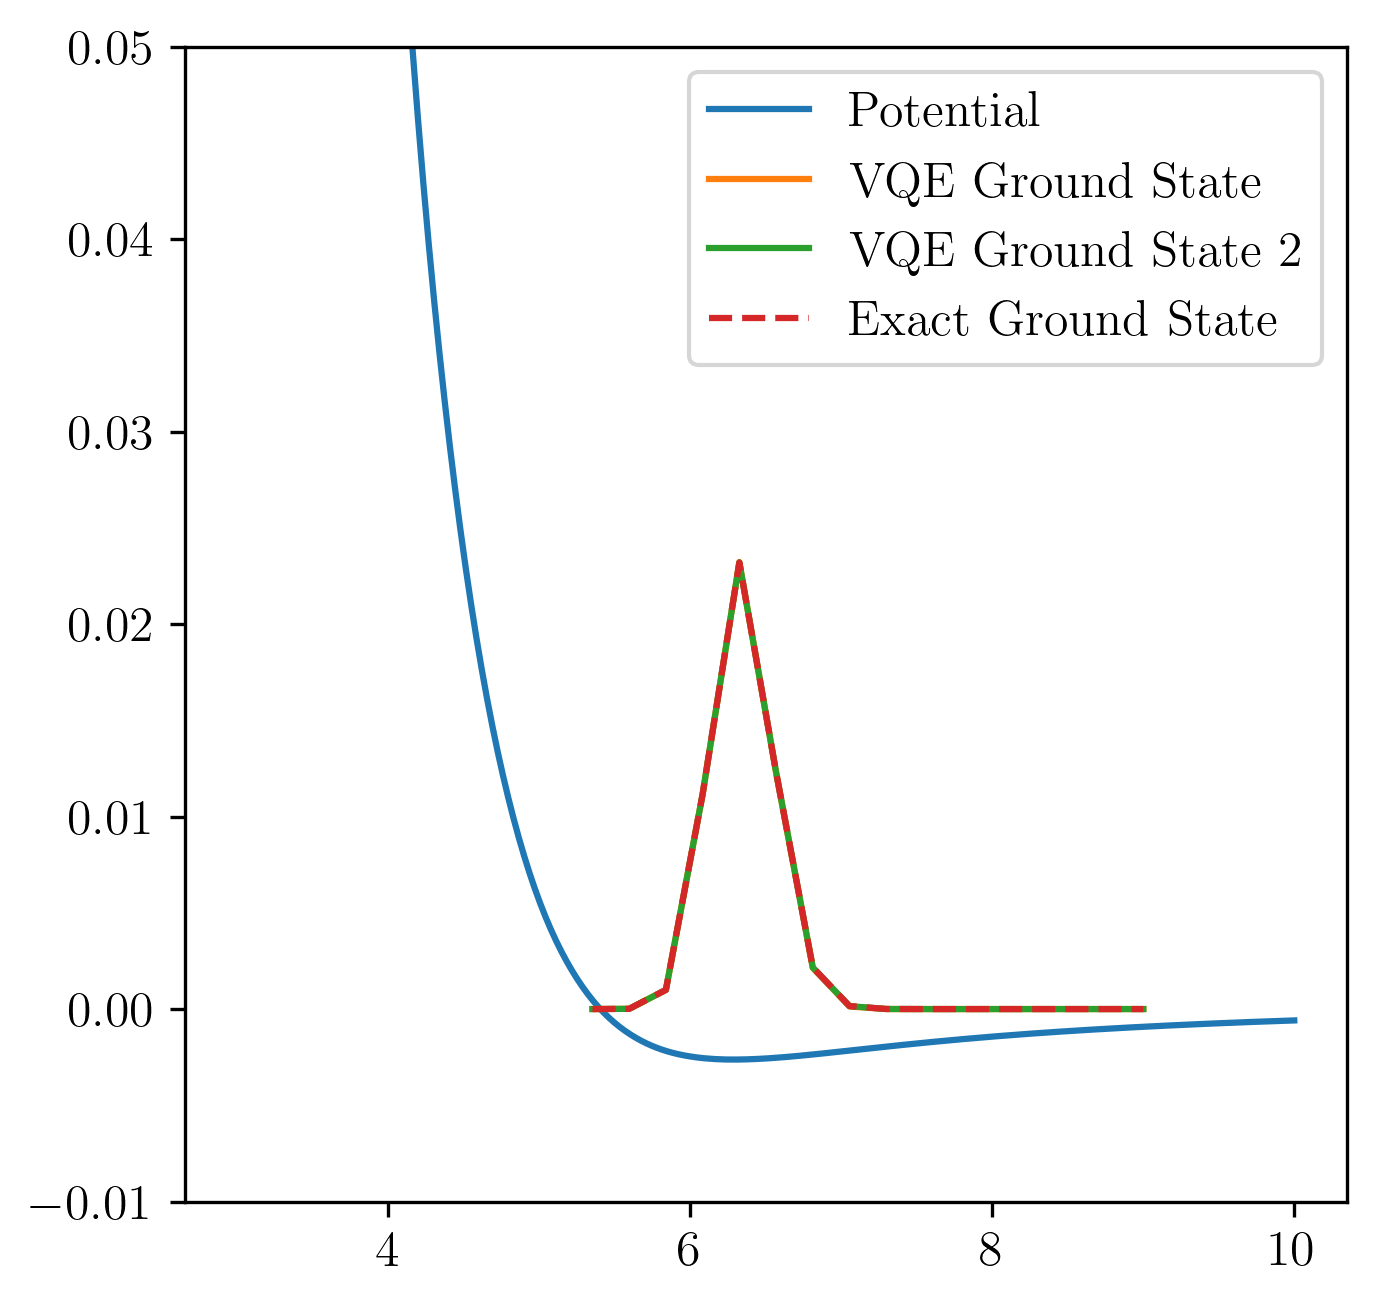

In [100]:
from lib.dvr1d import get_dvr_r, dvr_0inf

dvr_options_exact = {
    'type': '1d',
    'box_lims': (4, 10),
    'dx': (10 - 4) / 64,
    'count': 64
}
h_dvr = dvr_vqe.get_h_dvr(dvr_options, J=0) * hartree
e_vals, e_vecs = np.linalg.eigh(h_dvr)
print(e_vals)

xs = np.linspace(3, 10, 200)
Vs = pot(xs)
plt.plot(xs, Vs, label='Potential')
scale = np.max(np.abs(gs_sv)) / np.max(np.abs(e_vecs[:,0]))
scale2 = np.max(np.abs(gs_sv2)) / np.max(np.abs(e_vecs[:,0]))
print(scale.real)
plt.plot(get_dvr_r(dvr_options), np.abs(gs_sv)**2 / scale / 20, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options), np.abs(gs_sv2)**2 / scale2 / 20, label='VQE Ground State 2')
plt.plot(get_dvr_r(dvr_options), np.abs(e_vecs[:,0])**2 / 20, label='Exact Ground State', ls='--')
plt.ylim(-0.01, 0.05)
plt.legend()



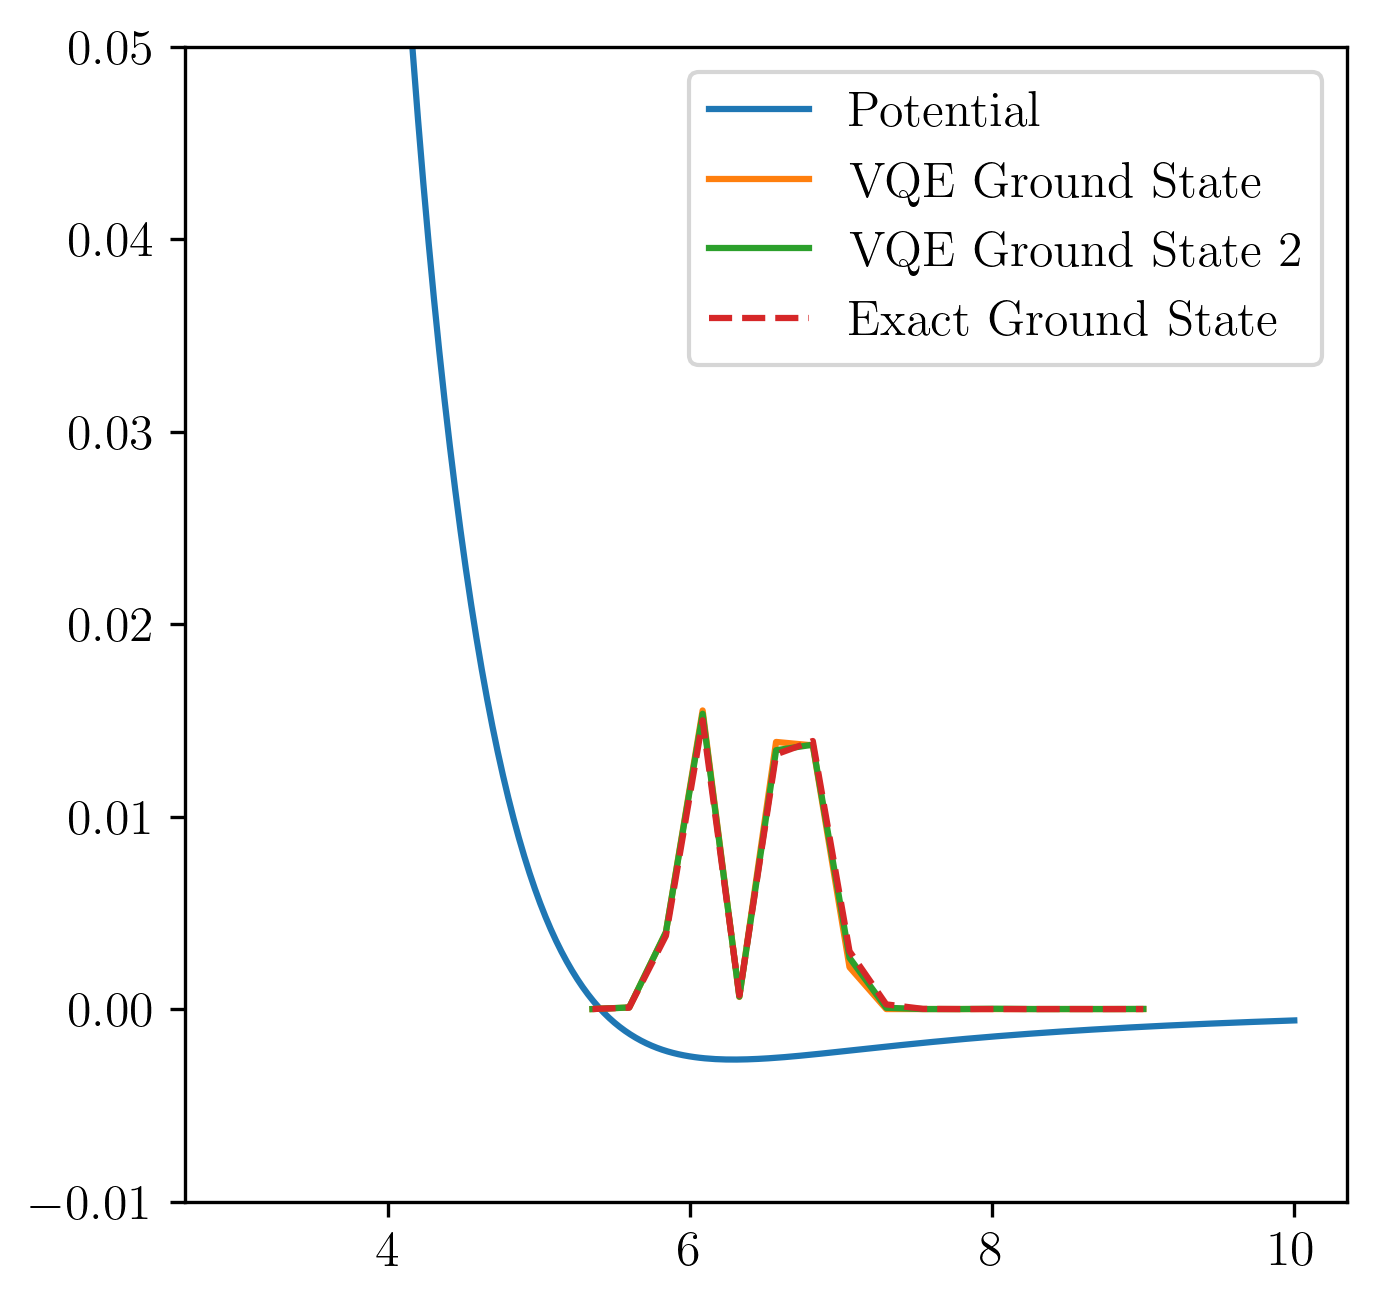

In [101]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), np.abs(es1_sv)**2 / scale / 20, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options), np.abs(es1_sv2)**2 / scale2 / 20, label='VQE Ground State 2')
plt.plot(get_dvr_r(dvr_options), np.abs(e_vecs[:,1])**2 / 20, label='Exact Ground State', ls='--')
plt.ylim(-0.01, 0.05)
plt.legend()

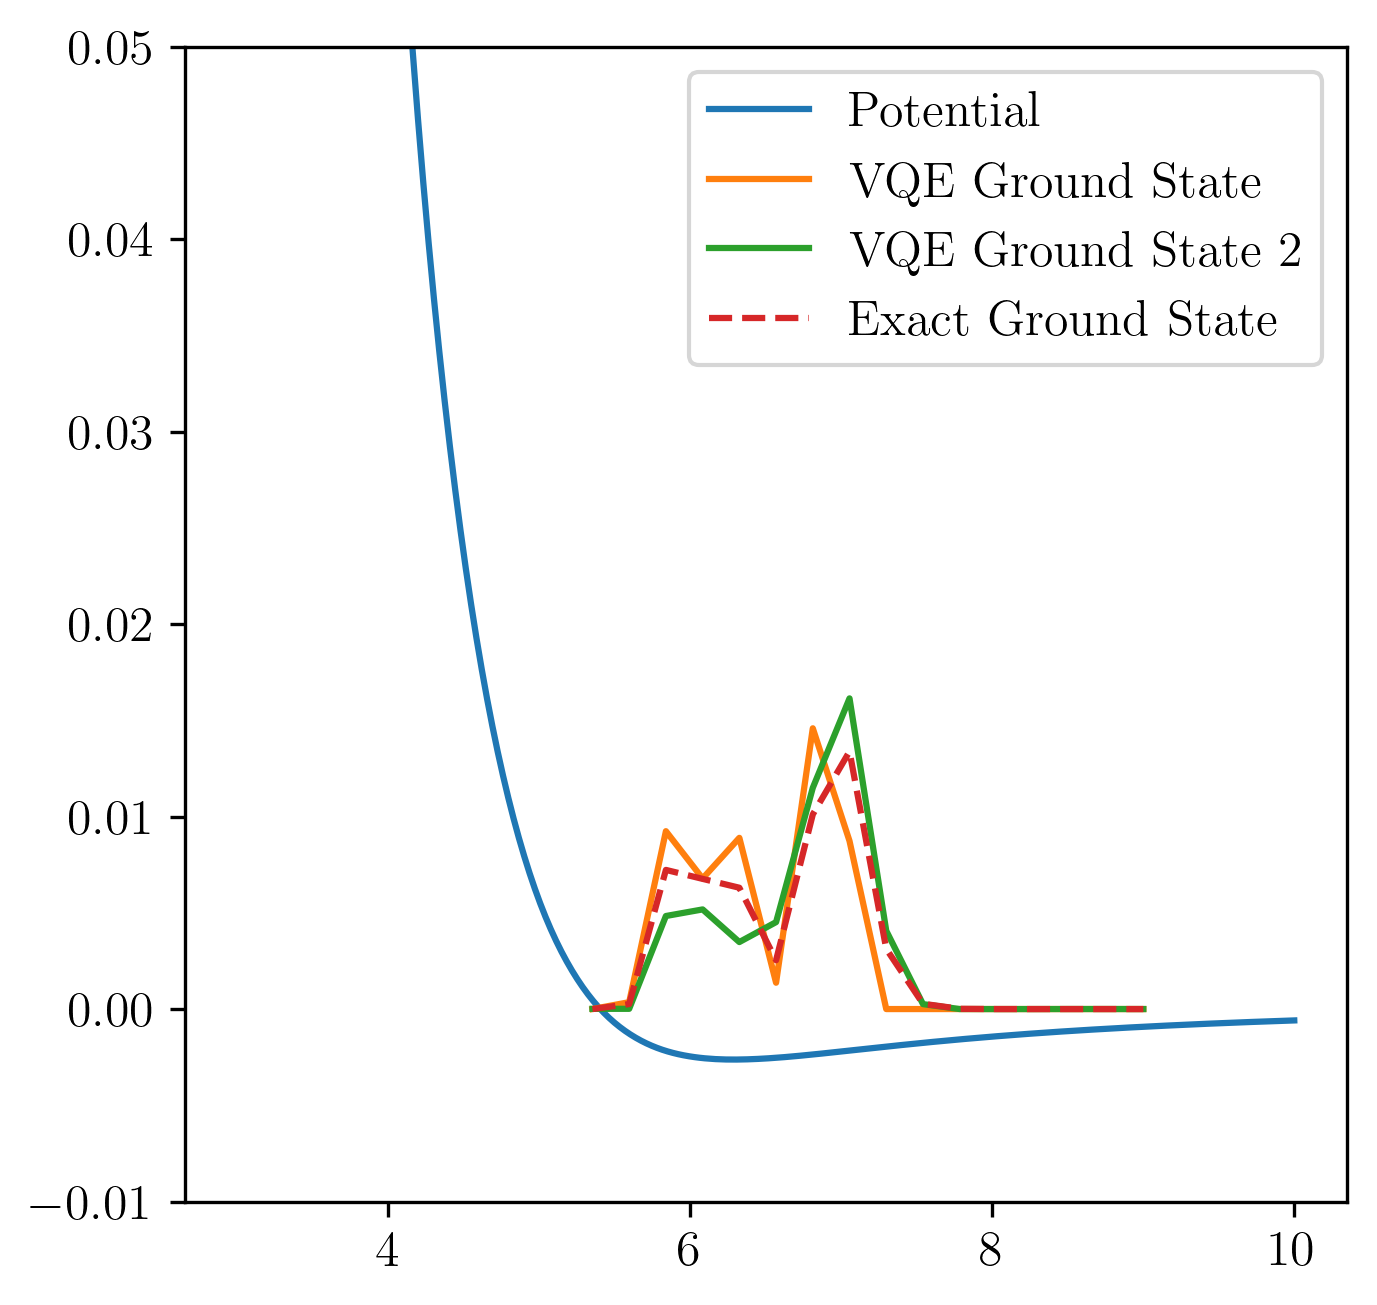

In [102]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), np.abs(es2_sv)**2 / scale / 20, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options), np.abs(es2_sv2)**2 / scale2 / 20, label='VQE Ground State 2')
plt.plot(get_dvr_r(dvr_options), np.abs(e_vecs[:,2])**2 / 20, label='Exact Ground State', ls='--')
plt.ylim(-0.01, 0.05)
plt.legend()

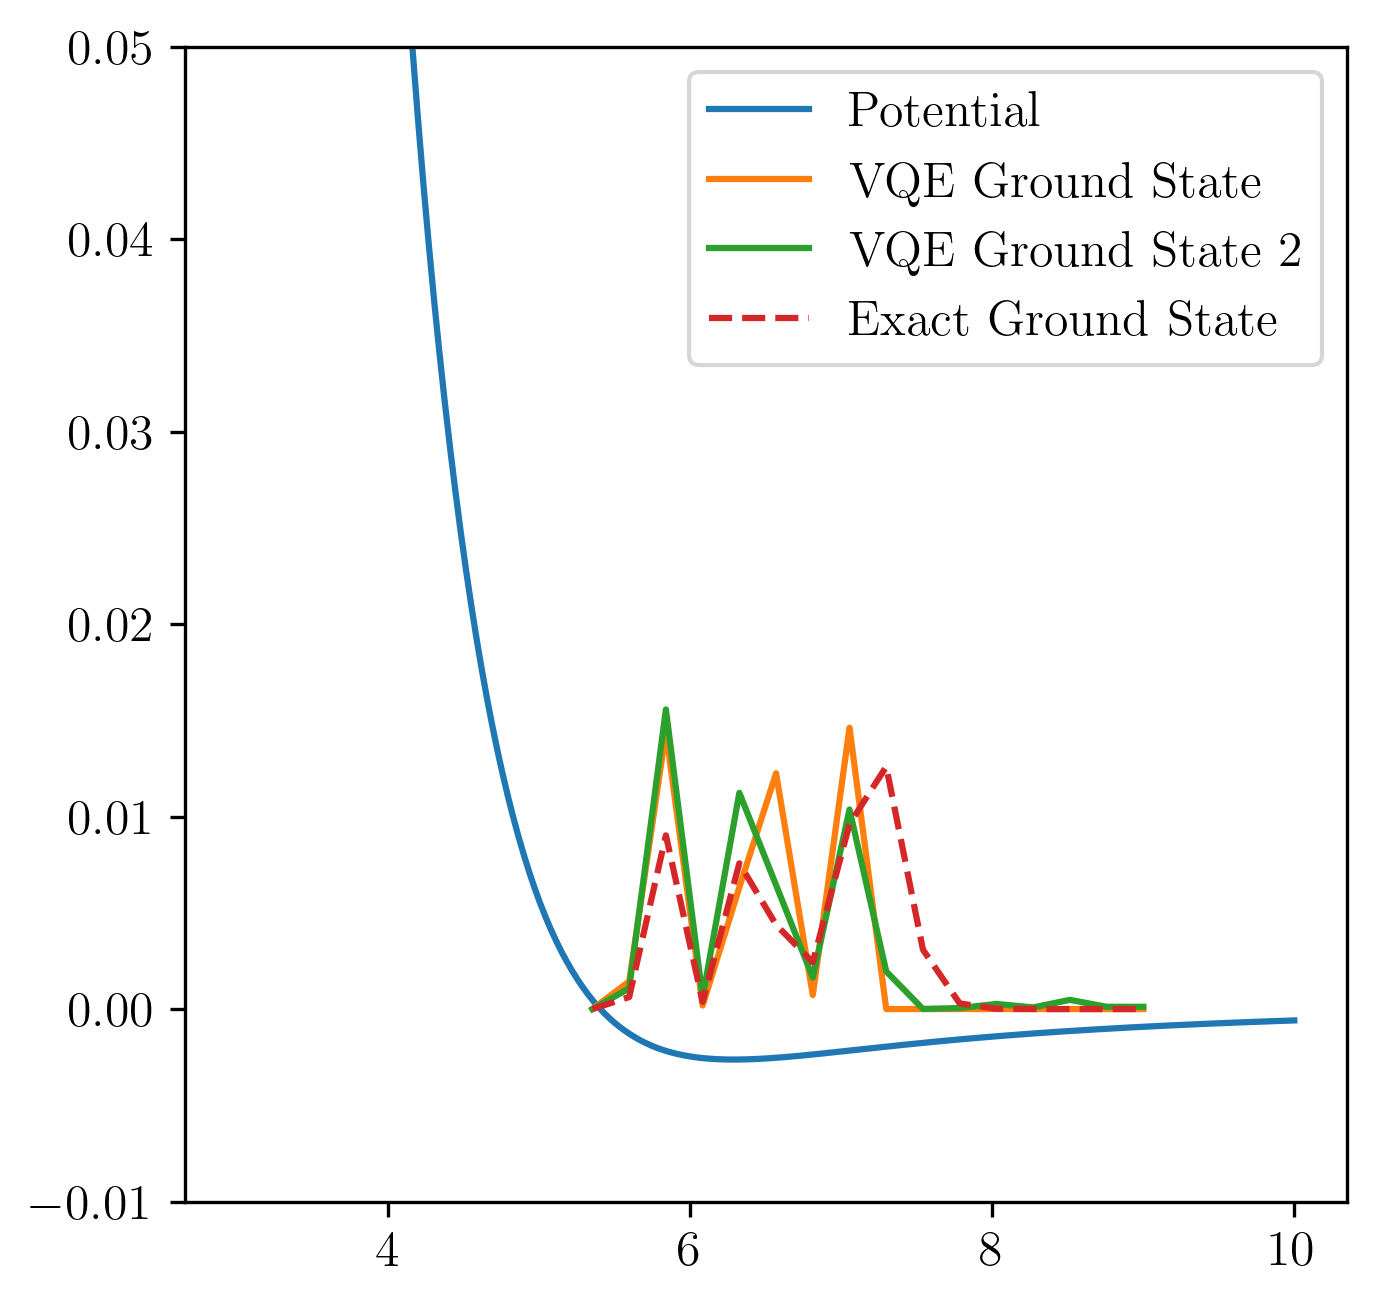

In [103]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), np.abs(es3_sv)**2 / scale / 20, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options), np.abs(es3_sv2)**2 / scale2 / 20, label='VQE Ground State 2')
plt.plot(get_dvr_r(dvr_options), np.abs(e_vecs[:,3])**2 / 20, label='Exact Ground State', ls='--')
plt.ylim(-0.01, 0.05)
plt.legend()

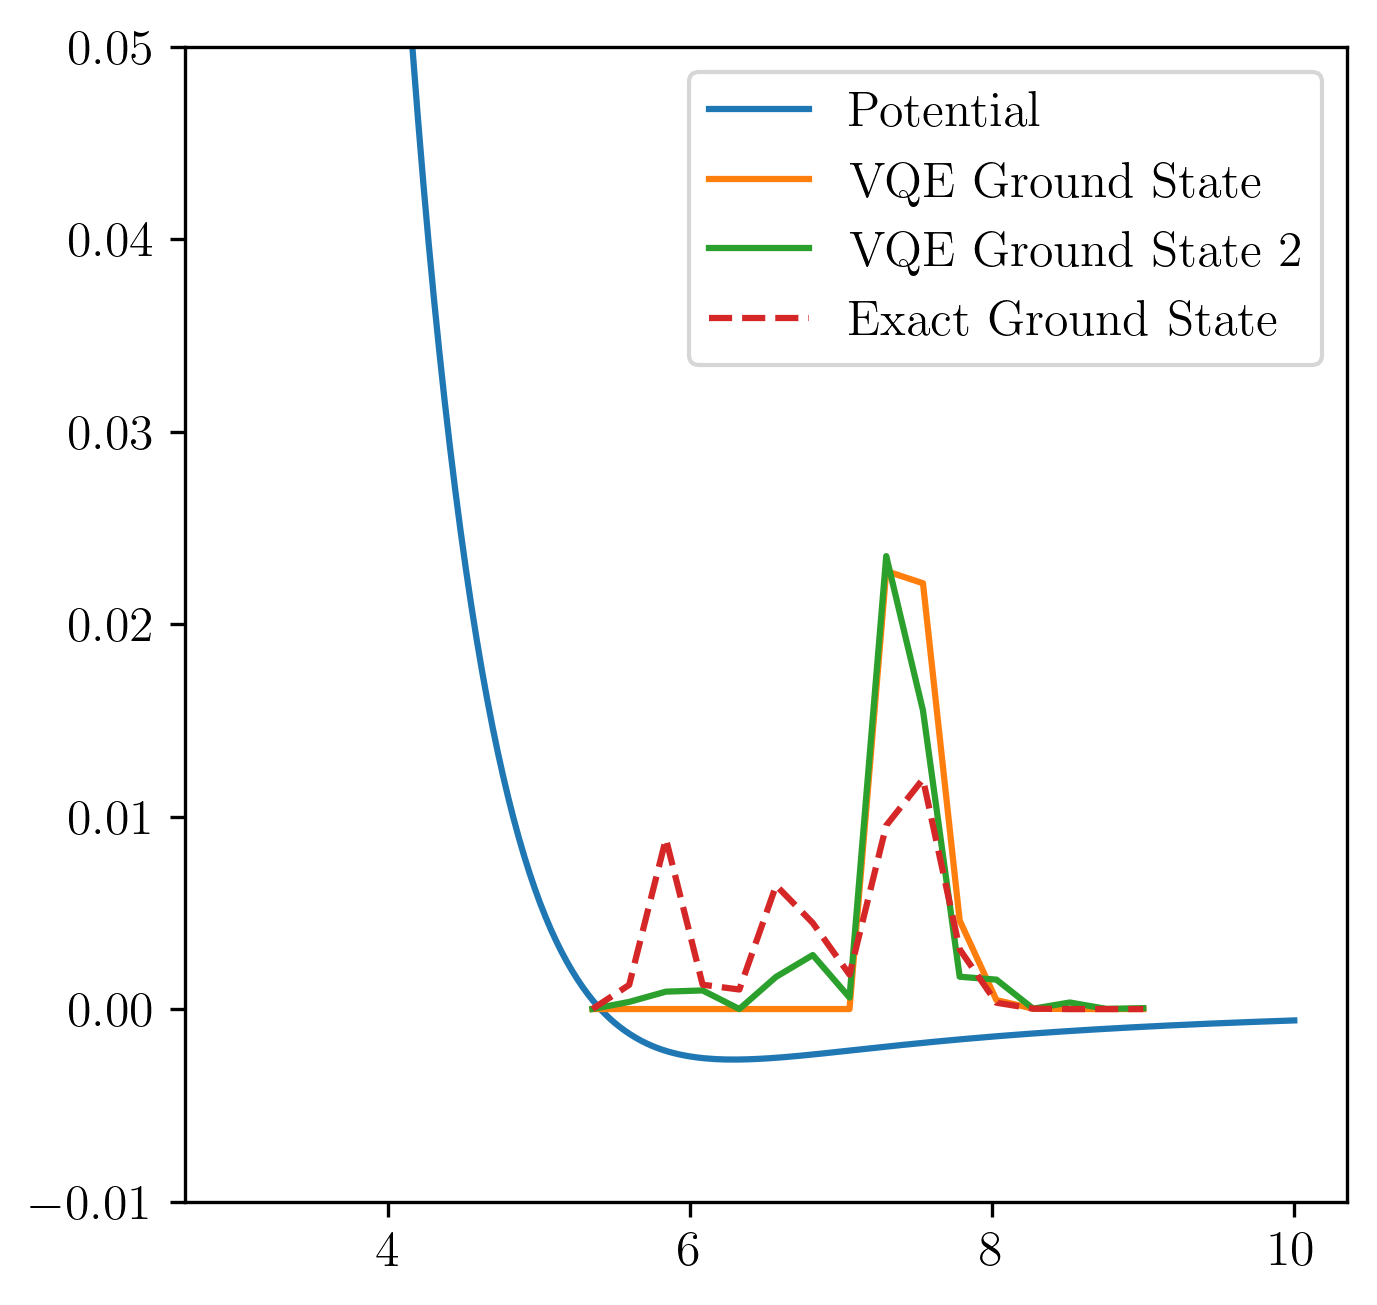

In [104]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), np.abs(es4_sv)**2 / scale / 20, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options), np.abs(es4_sv2)**2 / scale2 / 20, label='VQE Ground State 2')
plt.plot(get_dvr_r(dvr_options), np.abs(e_vecs[:,4])**2 / 20, label='Exact Ground State', ls='--')
plt.ylim(-0.01, 0.05)
plt.legend()

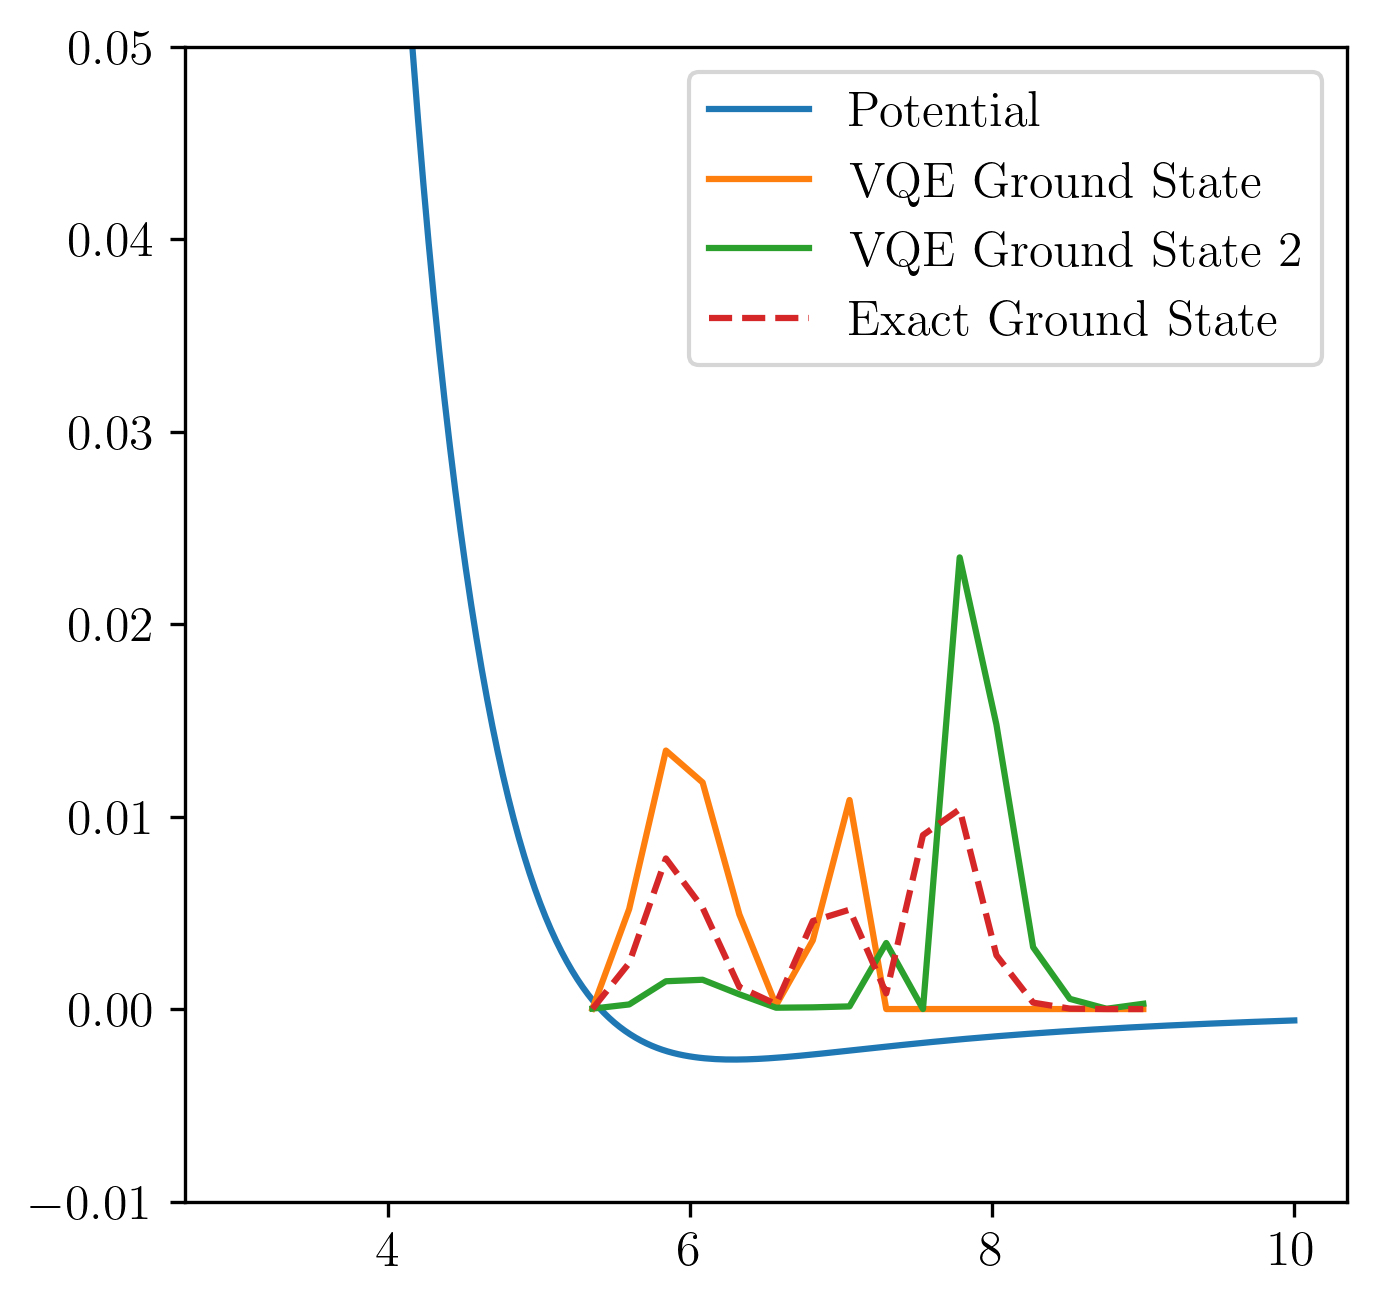

In [105]:
plt.plot(xs, Vs, label='Potential')
plt.plot(get_dvr_r(dvr_options), np.abs(es5_sv)**2 / scale / 20, label='VQE Ground State')
plt.plot(get_dvr_r(dvr_options), np.abs(es5_sv2)**2 / scale2 / 20, label='VQE Ground State 2')
plt.plot(get_dvr_r(dvr_options), np.abs(e_vecs[:,5])**2 / 20, label='Exact Ground State', ls='--')
plt.ylim(-0.01, 0.05)
plt.legend()

In [106]:
fid1s = []
for i in range(6):
    fid1 = np.abs(np.dot(sv1s[i], e_vecs[:,i].conj()))**2
    fid1s.append(fid1)
    print(f'Fidelity VQE 1 state {i}: {fid1}')
print('----')
fid2s = []
for i in range(6):
    fid2 = np.abs(np.dot(sv2s[i], e_vecs[:,i].conj()))**2
    fid2s.append(fid2)
    print(f'Fidelity VQE 2 state {i}: {fid2}')

Fidelity VQE 1 state 0: 0.9998698300393369
Fidelity VQE 1 state 1: 0.9932521402811314
Fidelity VQE 1 state 2: 0.9052771335486609
Fidelity VQE 1 state 3: 0.5439336303261224
Fidelity VQE 1 state 4: 0.49535707599428586
Fidelity VQE 1 state 5: 0.49956614157208695
----
Fidelity VQE 2 state 0: 0.9999888775431531
Fidelity VQE 2 state 1: 0.997820242395863
Fidelity VQE 2 state 2: 0.9710579402019418
Fidelity VQE 2 state 3: 0.7899136974474193
Fidelity VQE 2 state 4: 0.7749093640686359
Fidelity VQE 2 state 5: 0.38542642078703193


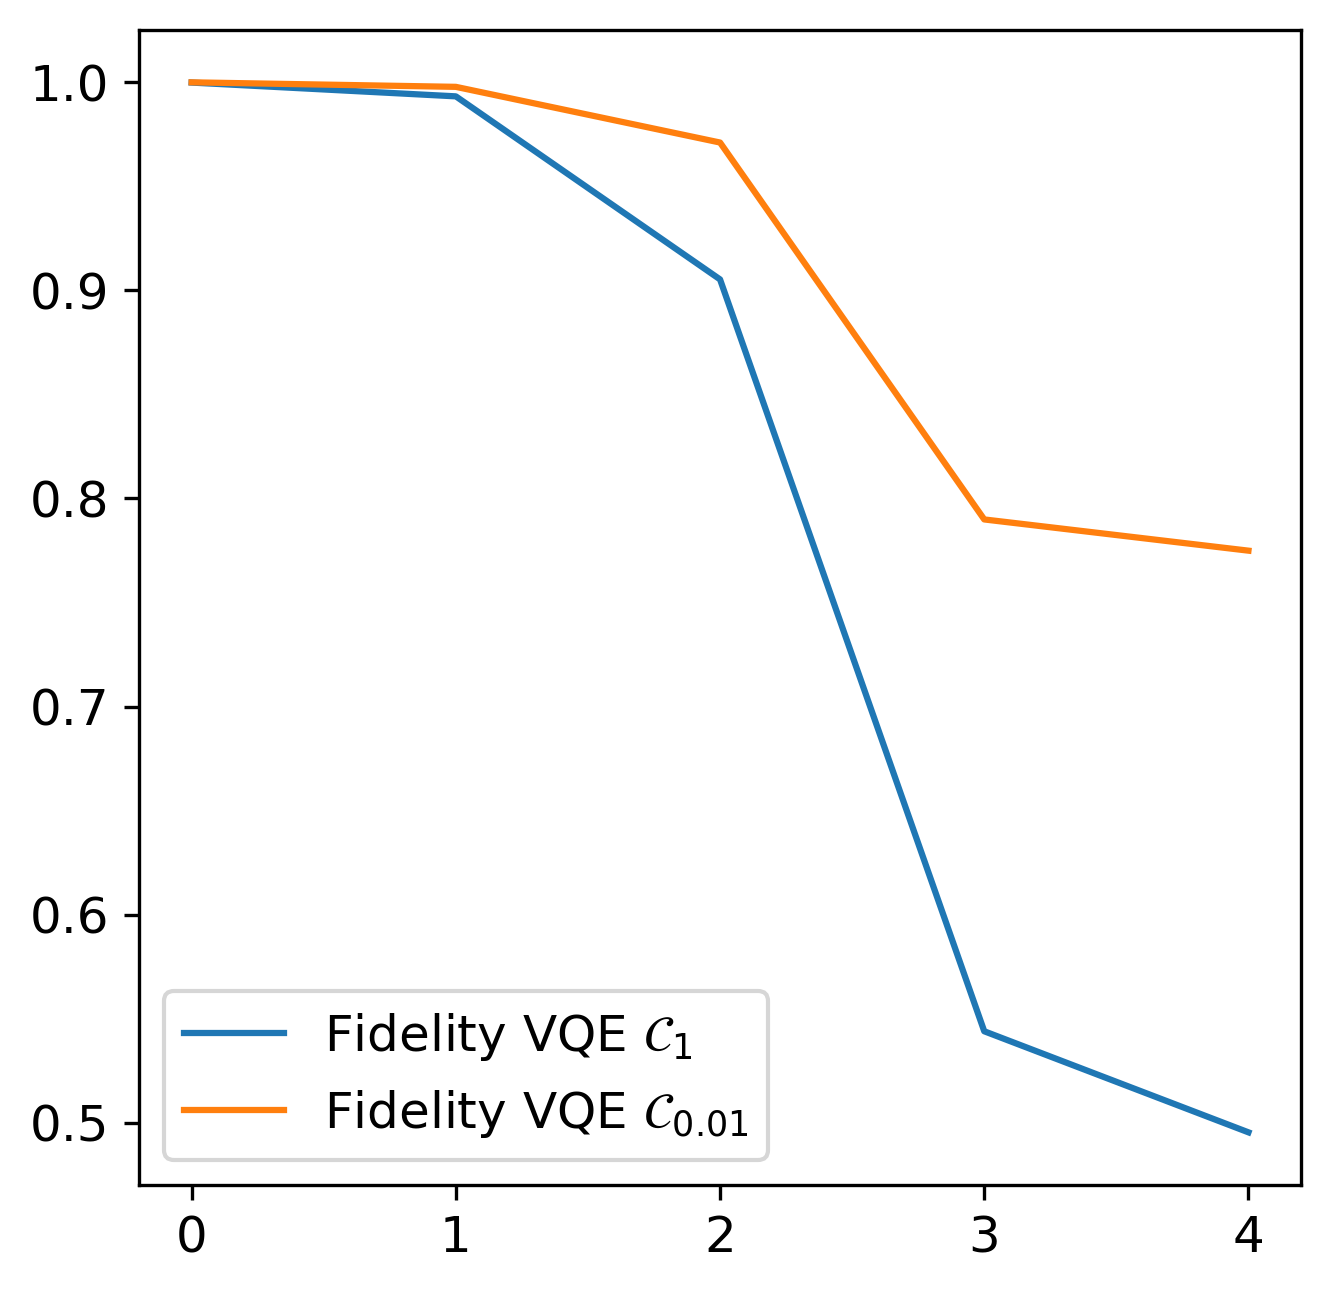

In [89]:
plt.plot(fid1s, label='Fidelity VQE $\mathcal{C}_1$')
plt.plot(fid2s, label='Fidelity VQE $\mathcal{C}_{0.01}$')
plt.legend()